# 06 — Robustness and sensitivity analysis

This notebook compares two-state Gaussian Markov return models with switching means and variances. M1 has constant transitions; M3, M4 and M5 use GPR, VIX and both lagged predictors. Each controlled comparison uses identical observations. Forecasts use only filtered states and one-step transitions, with test parameters estimated through 2019. Historical revised GPR supports pseudo-out-of-sample evaluation only.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd() if (Path.cwd() / "data" / "processed").is_dir() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "code"))
from stage06_robustness import run, TABLES, FIGURES
from IPython.display import display, Markdown, Image
results = run()

## Source and information timing audit

WTI log returns are `100 log(current positive spot price / previous observed positive spot price)`. The negative WTI price on 2020-04-20 makes that date’s return undefined; 2020-04-21 also lacks a return because its previous observed price was negative. The 2020-04-22 return and later valid pandemic returns remain. VIX lag 5 means the fifth preceding nonmissing VIX market observation; GPR lag 5 means exactly five calendar days before the return. Original lags retain Stage 04 definitions. Forecasting treats valid returns as successive model observations even when calendar intervals differ. Revised GPR publication timing remains unverified.

In [2]:
display(Markdown("### Brent versus WTI in-sample model rankings (compare only within benchmark)"))
display(results["comparison"].round(4))
display(Markdown("### WTI regime means, standard deviations, persistence and occupancy"))
display(results["regimes"].query("case == 'wti_training'").round(4))

### Brent versus WTI in-sample model rankings (compare only within benchmark)

,model,observations,log_likelihood,aic,bic,benchmark,aic_rank_within_benchmark,bic_rank_within_benchmark
0,M1,3699,-8042.6257,16097.2514,16134.5463,Brent,4,3
1,M3,3699,-8035.5089,16087.0177,16136.7443,Brent,3,4
2,M4,3699,-8029.9971,16075.9942,16125.7208,Brent,2,1
3,M5,3699,-8025.5906,16071.1812,16133.3394,Brent,1,2
4,M1,3633,-8170.1568,16352.3135,16389.5004,WTI,4,2
5,M3,3633,-8166.4168,16348.8335,16398.4160,WTI,3,4
6,M4,3633,-8158.0218,16332.0435,16381.6260,WTI,1,1
7,M5,3633,-8156.5428,16333.0855,16395.0637,WTI,2,3


### WTI regime means, standard deviations, persistence and occupancy

,case,model,state,original_state,mean_pct,sd_pct,stay_probability_at_median,stay_probability_training_average,mean_filtered_occupancy,mean_smoothed_occupancy_retrospective,expected_duration_observations_at_median
0,wti_training,M1,Low,0,0.0973,1.7998,0.9803,0.9803,0.7948,0.7907,50.6370
1,wti_training,M1,High,1,-0.3277,4.4448,0.9258,0.9258,0.2052,0.2093,13.4824
2,wti_training,M3,Low,0,0.0986,1.7902,0.9827,0.9762,0.7899,0.7848,57.6419
3,wti_training,M3,High,1,-0.3210,4.4079,0.9293,0.9256,0.2101,0.2152,14.1375
4,wti_training,M4,Low,0,0.0908,1.8454,0.9746,0.9702,0.8416,0.8390,39.3088
5,wti_training,M4,High,1,-0.4216,4.8803,0.7904,0.7980,0.1584,0.1610,4.7707
6,wti_training,M5,Low,0,0.0927,1.8378,0.9755,0.9699,0.8367,0.8337,40.7767
7,wti_training,M5,High,1,-0.4149,4.8269,0.7981,0.8041,0.1633,0.1663,4.9537


In [3]:
display(Markdown("### WTI validation and test forecasts"))
display(results["wti_performance"].round(5))
display(Markdown("### WTI paired QLIKE uncertainty"))
display(results["wti_comparison"].round(5))

### WTI validation and test forecasts

,period,model,n,qlike,mse,log_score,mae
0,wti_test,M1,1703,3.14010,5292.07767,2.46420,12.98278
1,wti_test,M3,1703,3.14179,5292.58540,2.46428,13.01887
2,wti_test,M4,1703,3.10315,5272.97031,2.45126,12.96686
3,wti_test,M5,1703,3.10648,5274.58254,2.45288,12.99320
4,wti_validation,M1,1000,2.51790,140.49057,2.14188,5.99728
5,wti_validation,M3,1000,2.52010,140.62478,2.14176,5.99069
6,wti_validation,M4,1000,2.52057,137.41731,2.14742,5.76261
7,wti_validation,M5,1000,2.52294,137.63001,2.14701,5.78636


### WTI paired QLIKE uncertainty

,period,left,right,n,mean_qlike_left_minus_right,basic_ci95_low,basic_ci95_high,centered_block_bootstrap_p,block_length,bootstrap_replicates,seed
0,wti_validation,M1,M3,1000,-0.00220,-0.00709,0.00366,0.40930,10,2000,7205
1,wti_validation,M1,M4,1000,-0.00266,-0.02199,0.01929,0.79910,10,2000,7205
2,wti_validation,M1,M5,1000,-0.00504,-0.02378,0.01554,0.61319,10,2000,7205
3,wti_validation,M4,M5,1000,-0.00238,-0.00567,0.00089,0.14793,10,2000,7205
4,wti_test,M1,M3,1703,-0.00169,-0.00912,0.00478,0.64068,10,2000,7205
5,wti_test,M1,M4,1703,0.03696,-0.00571,0.06777,0.04748,10,2000,7205
6,wti_test,M1,M5,1703,0.03363,-0.00662,0.06290,0.05247,10,2000,7205
7,wti_test,M4,M5,1703,-0.00333,-0.00840,0.00182,0.20890,10,2000,7205


In [4]:
display(Markdown("### Brent and WTI transition coefficients"))
from pandas import read_csv
coefs=read_csv(TABLES / "06_brent_wti_coefficients.csv")
display(coefs.loc[coefs.parameter.str.contains("tvtp")].round(5))
display(Markdown("### Probability scenario contrasts, p90 minus p10"))
display(results["scenarios"].query("case == 'wti_training'").round(5))

### Brent and WTI transition coefficients

,case,model,parameter,estimate,std_error
6,brent_original,M3,p[0->0].tvtp0,4.06357,0.29905
7,brent_original,M3,p[1->0].tvtp0,-2.86989,0.27915
8,brent_original,M3,p[0->0].tvtp1,-0.93603,0.19145
9,brent_original,M3,p[1->0].tvtp1,0.47946,0.19678
14,brent_original,M4,p[0->0].tvtp0,3.34537,0.26801
15,brent_original,M4,p[1->0].tvtp0,-2.15864,0.32097
16,brent_original,M4,p[0->0].tvtp1,0.11676,0.27059
17,brent_original,M4,p[1->0].tvtp1,-1.17554,0.39667
22,brent_original,M5,p[0->0].tvtp0,3.60506,0.30666
23,brent_original,M5,p[1->0].tvtp0,-2.27865,0.29122


### Probability scenario contrasts, p90 minus p10

,case,model,predictor,transition,raw_p10,raw_p90,probability_p10,probability_p90,p90_minus_p10,delta_se,delta_ci95_low,delta_ci95_high
0,wti_training,M3,gpr,low_to_high,51.57293,162.94178,0.01273,0.03027,0.01754,0.00755,0.00275,0.03234
1,wti_training,M3,gpr,high_to_high,51.57293,162.94178,0.93637,0.91449,-0.02188,0.02369,-0.06832,0.02456
2,wti_training,M4,vix,low_to_high,12.39000,31.59600,0.01998,0.04174,0.02176,0.01341,-0.00453,0.04804
3,wti_training,M4,vix,high_to_high,12.39000,31.59600,0.69848,0.91191,0.21343,0.10284,0.01186,0.41501
4,wti_training,M5,gpr,low_to_high,51.57293,162.94178,0.02073,0.03319,0.01245,0.00909,-0.00536,0.03027
5,wti_training,M5,gpr,high_to_high,51.57293,162.94178,0.80197,0.79104,-0.01092,0.05655,-0.12176,0.09991
6,wti_training,M5,vix,low_to_high,12.39000,31.59600,0.02095,0.03391,0.01295,0.01328,-0.01307,0.03898
7,wti_training,M5,vix,high_to_high,12.39000,31.59600,0.70652,0.91706,0.21053,0.10786,-0.00087,0.42194


In [5]:
display(Markdown("### Lag validation performance"))
display(results["lag_performance"].round(5))
display(Markdown("### GPR level versus log(1 + GPR)"))
display(results["transform_performance"].round(5))
display(Markdown("### Original versus 2007-start validation"))
display(results["early_performance"].round(5))
display(Markdown("### Same-sample lag model fit"))
display(read_csv(TABLES / "06_alternative_lag_fit.csv").round(4))
display(Markdown("### Same-sample GPR transformation fit"))
display(read_csv(TABLES / "06_gpr_transform_fit.csv").round(4))

### Lag validation performance

,period,model,n,qlike,mse,log_score,mae
0,original_lags,M1,999,2.44202,90.68253,2.13269,5.41134
1,original_lags,M3,999,2.44782,91.00828,2.13579,5.43251
2,original_lags,M4,999,2.44205,89.64232,2.13095,5.14648
3,original_lags,M5,999,2.44502,89.72392,2.13230,5.19744
4,vix_lag5_observations,M4,999,2.44142,89.77181,2.13059,5.18498
5,vix_lag5_observations,M5,999,2.44558,89.93265,2.13283,5.24117
6,gpr_lag5_calendar_days,M3,999,2.44497,90.83056,2.13434,5.42608
7,gpr_lag5_calendar_days,M5,999,2.44432,89.66590,2.13162,5.18678


### GPR level versus log(1 + GPR)

,period,model,n,qlike,mse,log_score,mae
0,gpr_level,M5,999,2.44502,89.72392,2.13230,5.19744
1,gpr_log1p,M5,999,2.44535,89.79275,2.13231,5.20566


### Original versus 2007-start validation

,period,model,n,qlike,mse,log_score,mae,training
0,validation,M1,999,2.44202,90.68253,2.13269,5.41134,2000-2015
1,validation,M3,999,2.44782,91.00828,2.13579,5.43251,2000-2015
2,validation,M4,999,2.44205,89.64232,2.13095,5.14648,2000-2015
3,validation,M5,999,2.44502,89.72392,2.13230,5.19744,2000-2015
4,validation_2007_start,M1,999,2.44629,91.40268,2.13861,5.31321,2007-2015
5,validation_2007_start,M3,999,2.44681,91.50086,2.13898,5.32688,2007-2015
6,validation_2007_start,M4,999,2.50272,92.89505,2.16018,4.69875,2007-2015
7,validation_2007_start,M5,999,2.50213,92.89073,2.16001,4.69566,2007-2015


### Same-sample lag model fit

,model,n,llf,aic,bic,case
0,M3,3699,-8035.5089,16087.0177,16136.7443,brent_original
1,M4,3699,-8029.9971,16075.9942,16125.7208,brent_original
2,M5,3699,-8025.5906,16071.1812,16133.3394,brent_original
3,M4,3699,-8031.8635,16079.7269,16129.4535,vix_lag5_observations
4,M5,3699,-8027.1140,16074.2279,16136.3861,vix_lag5_observations
5,M3,3699,-8037.4172,16090.8343,16140.5609,gpr_lag5_calendar_days
6,M5,3699,-8025.4899,16070.9799,16133.1381,gpr_lag5_calendar_days


### Same-sample GPR transformation fit

,model,n,llf,aic,bic,case
0,M5,3699,-8025.5906,16071.1812,16133.3394,gpr_level
1,M5,3699,-8026.4732,16072.9463,16135.1045,gpr_log1p


In [6]:
display(Markdown("### Transition effect comparisons"))
display(results["effects"].loc[results["effects"].model.eq("M5"),["case","model","predictor","transition","p90_minus_p10","delta_ci95_low","delta_ci95_high"]].round(5))
display(Markdown("### Convergence and stability"))
display(results["diagnostics"][["case","model","n","llf","successful_starts","ll_spread","missing_se","min_transition"]].round(6))
print("Failed starts:",int((~results["attempts"].valid).sum()),"warnings:",int(results["attempts"].warning_count.sum()))
display(Markdown("### M5 transition coefficients across variants"))
display(results["coefficients"].loc[results["coefficients"].model.eq("M5") & results["coefficients"].parameter.str.contains("tvtp"),["case","parameter","estimate","std_error"]].round(5))

### Transition effect comparisons

,case,model,predictor,transition,p90_minus_p10,delta_ci95_low,delta_ci95_high
8,wti_training,M5,gpr,low_to_high,0.01245,-0.00536,0.03027
9,wti_training,M5,gpr,high_to_high,-0.01092,-0.12176,0.09991
10,wti_training,M5,vix,low_to_high,0.01295,-0.01307,0.03898
11,wti_training,M5,vix,high_to_high,0.21053,-0.00087,0.42194
12,brent_original,M5,gpr,low_to_high,0.03565,0.01066,0.06064
13,brent_original,M5,gpr,high_to_high,-0.05093,-0.14799,0.04612
14,brent_original,M5,vix,low_to_high,-0.01295,-0.03745,0.01155
15,brent_original,M5,vix,high_to_high,0.19298,0.02505,0.36091
18,vix_lag5_observations,M5,gpr,low_to_high,0.03767,0.01550,0.05984
19,vix_lag5_observations,M5,gpr,high_to_high,-0.06565,-0.13493,0.00363


### Convergence and stability

,case,model,n,llf,successful_starts,ll_spread,missing_se,min_transition
0,wti_training,M1,3633,-8170.156759,3,0.000002,0,0.019748
1,wti_training,M3,3633,-8166.416756,3,0.000003,0,0.008972
2,wti_training,M4,3633,-8158.021755,3,0.000021,0,0.002071
3,wti_training,M5,3633,-8156.542759,3,0.000006,0,0.001774
4,wti_test,M1,4633,-10308.665387,3,0.000000,0,0.018669
5,wti_test,M3,4633,-10305.167953,3,0.000004,0,0.008797
6,wti_test,M4,4633,-10298.390991,3,0.000016,0,0.004948
7,wti_test,M5,4633,-10296.649081,3,0.000022,0,0.003387
8,brent_original,M5,3699,-8025.590630,3,0.000004,0,0.000036
9,vix_lag5_observations,M4,3699,-8031.863472,3,0.000002,0,0.000117


Failed starts: 0 warnings: 0


### M5 transition coefficients across variants

,case,parameter,estimate,std_error
22,wti_training,p[0->0].tvtp0,3.57054,0.23246
23,wti_training,p[1->0].tvtp0,-1.54260,0.40923
24,wti_training,p[0->0].tvtp1,-0.28432,0.19692
25,wti_training,p[1->0].tvtp1,0.03966,0.20822
26,wti_training,p[0->0].tvtp2,-0.23433,0.22573
27,wti_training,p[1->0].tvtp2,-0.72224,0.24120
32,brent_original,p[0->0].tvtp0,3.60477,0.30660
33,brent_original,p[1->0].tvtp0,-2.27876,0.29118
34,brent_original,p[0->0].tvtp1,-0.71075,0.25774
35,brent_original,p[1->0].tvtp1,0.28246,0.27309


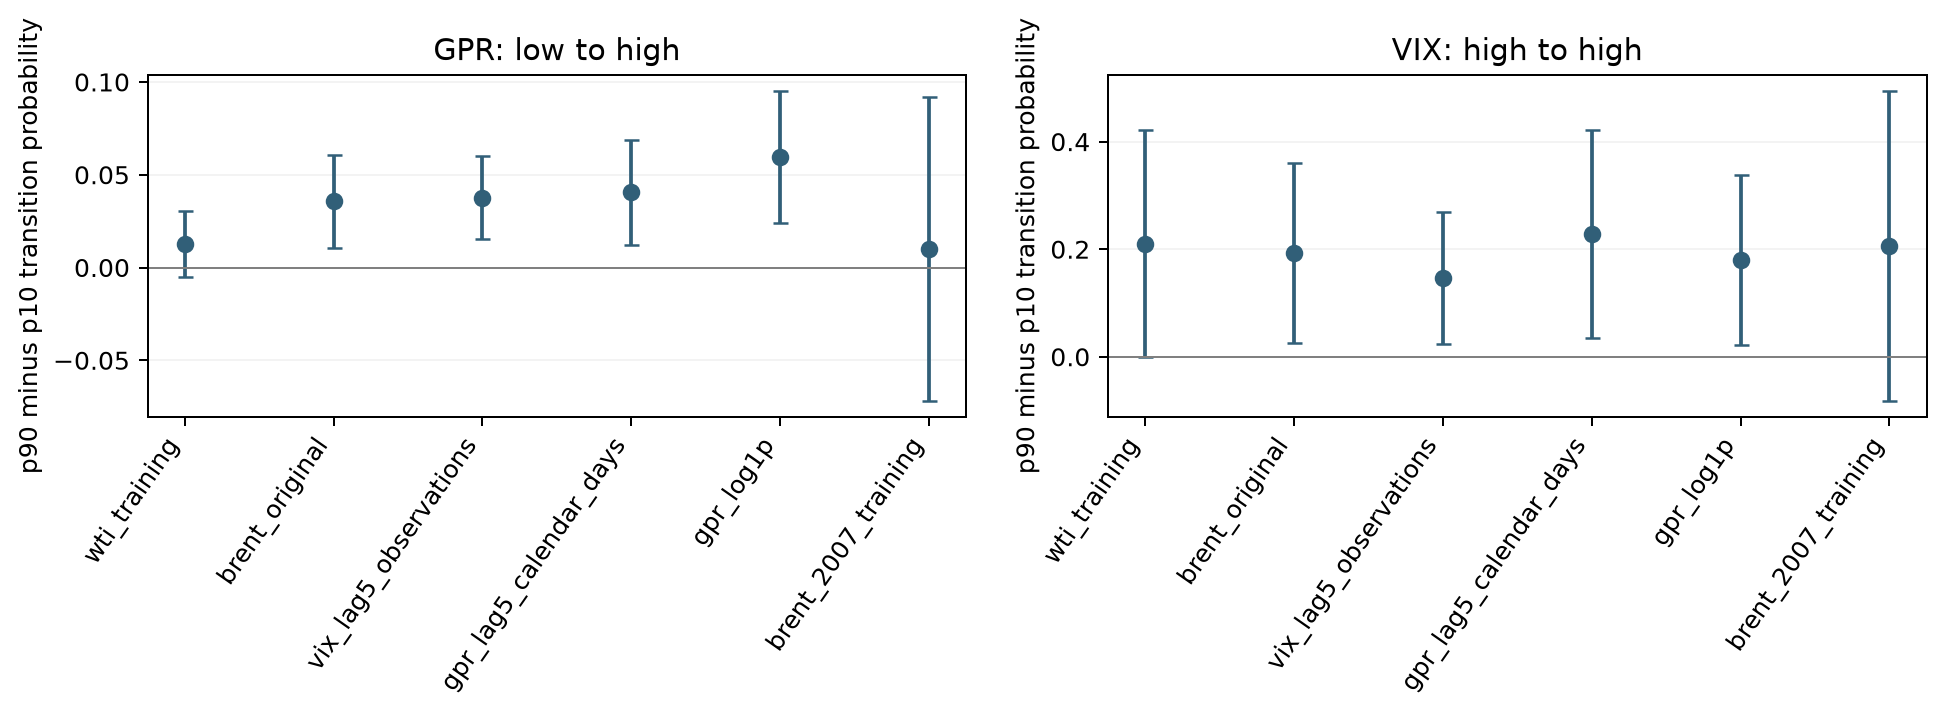

In [7]:
display(Image(filename=str(FIGURES / "06_transition_effect_robustness.png"), width=1000))

## Final research assessment

The table separates descriptive regime relationships from forecasting evidence. Probability contrasts are model-implied p90 minus p10 changes at the other predictor’s median. Their delta-method intervals are conditional on the fitted specification; the paired forecast-loss intervals use blocks of 10 observations. Neither establishes causality.

| Finding | Supporting evidence | Contradicting evidence | Robustness assessment |
|---|---|---|---|
| Distinct low/high WTI volatility regimes | WTI training state SDs are about 1.8 versus 4.4–4.9 percentage points; both states have meaningful occupancy. | Occupancy and persistence vary with the transition specification. | supported — descriptive two-state distinction |
| GPR and entry to high volatility | Brent M5 p90–p10 GPR contrast is about +0.036 (delta 95% CI +0.011 to +0.061); positive with five-day lag and log transform. | WTI M5 contrast is about +0.012 with interval crossing zero; 2007-start Brent contrast is near zero and uncertain. | mixed — sample and benchmark dependent |
| VIX and high-state persistence | M5 p90–p10 VIX contrast is positive in Brent (+0.193) and WTI (+0.211); Brent lag and transform variants retain positive contrasts. | WTI M5 interval narrowly crosses zero; 2007-start interval is wide and crosses zero. | mixed — direction stable, precision uneven |
| Incremental GPR forecasting value beyond VIX | Brent M5 numerically improves on M1 in the Stage 05 test. | Brent M5 versus M4 test difference is under 0.001 with interval crossing zero; WTI M5 is worse than M4 on validation and test QLIKE. | not supported — no consistent predictive gain |
| Alternative lag and GPR transform forecasts | Five-lag and log(1+GPR) Brent M5 validation QLIKE stays near 2.445 on identical dates. | GPR probability-contrast magnitude changes; original level has slightly better AIC/BIC than log transform. | mixed — forecast ranking stable, effect size changes |
| Shorter Brent training period | Regime variance ordering survives the 2007–2015 fit. | M5 validation QLIKE worsens from about 2.445 to 2.502; GPR contrast loses precision and VIX entry contrast changes sharply. | mixed — early coverage materially affects transitions |
| Real-time GPR predictive claim | Lagged revised historical GPR is associated with some fitted Brent transition probabilities. | Historical publication vintages and release timing are unverified; held-out incremental GPR gains are not reliable. | not supported — pseudo-out-of-sample evidence only |

The reliable thesis claims are the descriptive low/high volatility distinction and the absence of a consistent incremental GPR forecasting gain beyond VIX. The GPR entry and VIX persistence patterns should be stated as conditional, model-specific associations. The original 2000–2015 Brent sample remains the primary analysis; the 2007-start exercise is sensitivity evidence. WTI excludes only the undefined 2020-04-20 and 2020-04-21 log returns; subsequent valid pandemic observations remain. Revised GPR values are historical pseudo-out-of-sample inputs with unverified real-time availability.

**Stage 06 methodological gate: PASS, with substantive findings mixed.** All models used matched observations within each comparison, only filtered states entered forecasts, all 51 independent starts converged, and no fit warnings or missing standard errors were recorded. Some fitted transitions approach zero and the shorter sample changes economic interpretation; these remain unresolved limits.